# Eclat: count shared basket IDs

Turn baskets inside out: store the basket IDs for each item instead of the items for each basket. Find frequent groups by intersecting those IDs.

In [1]:
%pip install -q mlxtend

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\jtmp\claude\52f53c55ac394814\9653a363-e261-4334-8ab1-57ec3b1ffef0\scratchpad\venv\Scripts\python.exe -m pip install --upgrade pip


## Load and encode the baskets

The file contains 500 original synthetic baskets (CC0 1.0), one per row with no header. It plants some patterns, including pasta with sauce, so you have something to discover. One-hot encoding gives each item its own True/False column. A basket can have more than one True value.

In [2]:
import csv
from urllib.request import urlopen

import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

url = 'https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/grocery_baskets.csv'
with urlopen(url, timeout=30) as response:
    baskets = list(csv.reader(line.decode('utf-8') for line in response))

encoder = TransactionEncoder()
encoded = encoder.fit(baskets).transform(baskets)
transactions = pd.DataFrame(encoded, columns=encoder.columns_)
print(f'{len(baskets)} baskets, {len(encoder.columns_)} items')
transactions.head()

500 baskets, 9 items


,bread,cereal,cheese,coffee,eggs,milk,pasta,sauce,tea
0,True,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False
2,True,False,False,False,True,False,False,False,False
3,True,True,True,False,True,True,True,True,False
4,True,False,True,False,True,False,True,True,False


## Build and intersect ID lists

Read the baskets once to assign IDs. When two groups have the same prefix, intersect their ID sets to get the support of their union. Drop any extension below the cutoff. Eclat can save time when repeated data scans are expensive and the ID lists are short enough to intersect quickly.

In [3]:
def eclat(baskets, minimum_support):
    ids_by_item = {}
    for basket_id, basket in enumerate(baskets, start=1):
        for item in basket:
            ids_by_item.setdefault(item, set()).add(basket_id)

    found = {}
    total = len(baskets)

    def visit(prefix, extensions):
        for index, (item, ids) in enumerate(extensions):
            support = len(ids) / total
            if support < minimum_support:
                continue
            group = (*prefix, item)
            found[frozenset(group)] = support
            visit(group, [(other, ids & other_ids)
                          for other, other_ids in extensions[index + 1:]])

    visit((), sorted(ids_by_item.items()))
    return found

minimum_support = 0.12
vertical = eclat(baskets, minimum_support)
print(f'{len(vertical)} frequent groups')

21 frequent groups


## Check against mlxtend

Run Apriori at the same threshold and compare both the groups and their support. Then use mlxtend to compute confidence and lift from the Eclat groups. Eclat itself only mined support; the rules are a separate step.

In [4]:
from math import isclose

reference = apriori(transactions, min_support=minimum_support, use_colnames=True)
expected = dict(zip(reference['itemsets'], reference['support']))
assert vertical.keys() == expected.keys()
assert all(isclose(support, expected[group]) for group, support in vertical.items())
print('Eclat and Apriori agree.')

frequent = pd.DataFrame([(support, group) for group, support in vertical.items()],
                        columns=['support', 'itemsets'])

Eclat and Apriori agree.


In [5]:
rules = association_rules(frequent, metric='confidence', min_threshold=0.5)

def label(items):
    return ' + '.join(sorted(items))

rules['rule'] = [f'{label(left)} → {label(right)}'
                 for left, right in zip(rules['antecedents'], rules['consequents'])]
rules = rules.sort_values(['lift', 'rule'], ascending=[False, True])
rules[['rule', 'support', 'confidence', 'lift']].head(10)

,rule,support,confidence,lift
9,cheese + sauce → pasta,0.210,1.000000,2.645503
12,pasta → cheese + sauce,0.210,0.555556,2.645503
8,cheese + pasta → sauce,0.210,0.889831,2.571764
13,sauce → cheese + pasta,0.210,0.606936,2.571764
11,cheese → pasta + sauce,0.210,0.704698,2.463979
10,pasta + sauce → cheese,0.210,0.734266,2.463979
5,cereal + pasta → sauce,0.120,0.789474,2.281716
4,cereal + sauce → pasta,0.120,0.845070,2.235636
16,pasta → sauce,0.286,0.756614,2.186745
17,sauce → pasta,0.286,0.826590,2.186745


## See it

The dashed line marks lift = 1: the rule predicts its right side no better than the overall baseline. In the scatter, larger dots mean higher lift. A high-lift dot can still be far to the left, meaning relatively few baskets contain both sides.

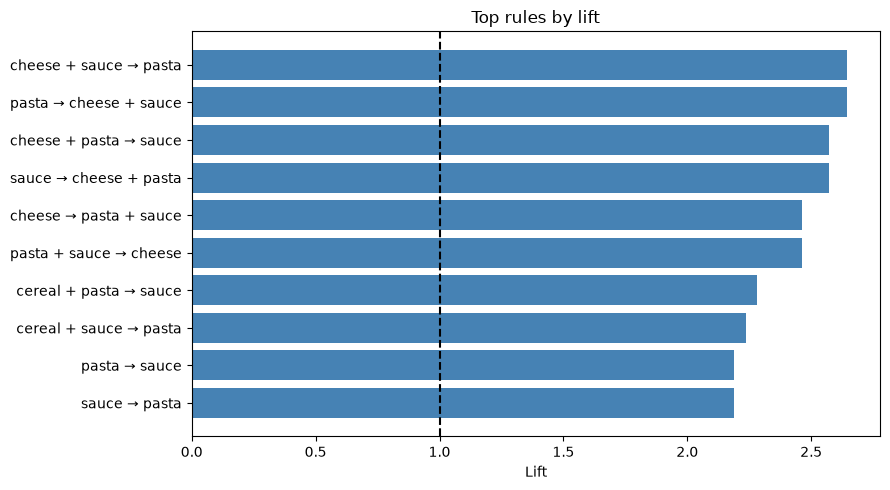

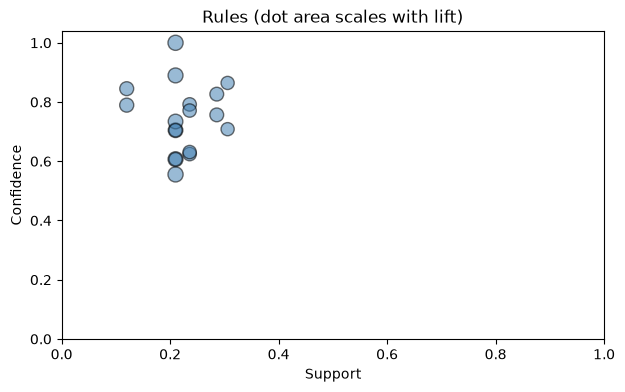

In [6]:
top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top['rule'], top['lift'], color='steelblue')
ax.axvline(1, color='black', linestyle='--')
ax.set(xlabel='Lift', title='Top rules by lift')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(rules['support'], rules['confidence'], s=45 * rules['lift'],
           alpha=0.55, color='steelblue', edgecolors='black')
ax.set(xlabel='Support', ylabel='Confidence', title='Rules (dot area scales with lift)',
       xlim=(0, 1), ylim=(0, 1.04))
plt.show()